# A1 · Spin Physics

**Part:** A – Physics of the MRI signal · **Reading time:** ~45 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [Precession and torque](../refreshers/RP3_Precession_and_Torque.ipynb), [Spin and thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb), [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb)

To understand MRI we must first understand *what is fundamentally being measured*: nuclear **spins**, and how they behave in a magnetic field. The single most important object in all of MRI is the **net magnetization** $\vec M$, the sum of all the tiny nuclear magnets in a small volume. This chapter introduces four ideas—**polarization, resonance, excitation/precession and relaxation**—at a physical, mostly non-mathematical level, but with real numbers attached. The precise mathematics (the Bloch equation) follows in [A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb).

## Learning goals

1. Understand what MRI is measuring
    * Define a nuclear spin (angular momentum, magnetic moment, gyromagnetic ratio)
    * Define the concept of the net magnetization and compute its size
1. Describe the concepts of polarization, resonance, excitation, and relaxation
    * Compute the equilibrium magnetization and fractional polarization at 1.5, 3 and 7 T
    * Explain resonance both classically (a driven "swing") and quantum mechanically (photon energy = energy gap)
    * Distinguish **precession** (rotation, fast, keeps the length of $\vec M$) from **relaxation** (return to equilibrium, slow, changes the length of $\vec M$)

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position in the scanner | m | $z$ along $B_0$ |
| $t$ | time | s | |
| $\vec B(\vec r,t)$ | magnetic flux density ("magnetic field") | T | Earth ≈ 50 µT |
| $B_0$ | main static field, along $z$ | T | 0.55, 1.5, 3, 7 T |
| $B_1$ | amplitude of the RF (radio-frequency) magnetic field, perpendicular to $B_0$ | T | 1–25 µT |
| $\vec L$ | angular momentum ("amount of rotation") of a spinning object | J s | |
| $\vec S$, $S_z$ | spin angular momentum of one nucleus; its $z$-component | J s | $S_z=\pm\hbar/2$ for ¹H |
| $I$ | spin quantum number of a nucleus | – | 1/2 for ¹H (original wrote $I_Z$) |
| $\vec\mu$, $\mu_z$ | magnetic moment of one nucleus; its $z$-component | J/T | $\mu_z=\gamma\hbar/2=1.41\times10^{-26}$ J/T for ¹H |
| $\vec\tau$ | torque (rotational "force") | N m = J | $\vec\tau=\vec\mu\times\vec B$ |
| $E$ | energy of a moment in a field, $E=-\vec\mu\cdot\vec B$ | J | |
| $\gamma$ | gyromagnetic ratio (angular), $\vec\mu=\gamma\vec S$ | rad s⁻¹ T⁻¹ | $2.675\times10^8$ for ¹H |
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio ("gamma-bar") | Hz/T | 42.58 MHz/T for ¹H |
| $f$, $\omega=2\pi f$ | (resonance) frequency; angular frequency | Hz; rad/s | |
| $f_0=\bar\gamma B_0$, $\omega_0=\gamma B_0$ | Larmor frequency | Hz; rad/s | 63.9 MHz @1.5 T, 127.7 MHz @3 T |
| $f_{rf}$, $\Delta f$ | frequency of the applied RF field; detuning $f_{rf}-f_0$ | Hz | |
| $h$, $\hbar=h/2\pi$ | Planck constant, reduced Planck constant | J s | $6.626\times10^{-34}$, $1.055\times10^{-34}$ |
| $k_B$ | Boltzmann constant | J/K | $1.381\times10^{-23}$ (original wrote $k$) |
| $T$ | absolute temperature (**not** tesla, **not** $T_1$/$T_2$) | K | 310 K body |
| $\Delta E$ | energy gap between the two ¹H spin states | J | $8.5\times10^{-26}$ J @3 T |
| $N(\vec r)$ | spin density (number of ¹H nuclei per volume) | m⁻³ | water: $6.7\times10^{28}$ |
| $N_\uparrow$, $N_\downarrow$ | number of spins in the lower ("up", parallel) / upper ("down") energy state | – | |
| $P$ | fractional polarization $(N_\uparrow-N_\downarrow)/(N_\uparrow+N_\downarrow)$ | – | ≈ 10 ppm @3 T |
| $\vec M(\vec r,t)=[M_x,M_y,M_z]^T$ | net magnetization (magnetic moment per volume) | A/m (normalized to $M_0=1$ in simulations) | |
| $M_0(\vec r)$ | equilibrium magnetization | A/m | ≈ 9 mA/m for water @3 T |
| $M_{xy}=M_x+iM_y$ | transverse magnetization (complex notation) | A/m | |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $T_1$, $T_2$ | longitudinal / transverse relaxation **time constants** | s | $T_1$ 0.25–4 s, $T_2$ 10 ms–2 s |
| $\theta$ | flip angle (tip of $\vec M$ away from $z$) | rad or ° | |
| $\alpha$ | tilt of the effective field away from $z$ (off-resonant driving) | rad | |

> **⚠️ Common confusion:** the letter $T$ is used for three different things: temperature $T$ [K], the unit tesla [T], and the relaxation times $T_1, T_2$ [s]. In this chapter the temperature always appears together with $k_B$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1 Nuclear spin

### 1.1 Angular momentum, magnetic moment, and the gyromagnetic ratio

Three physics words appear in every MRI text. Here is what they mean:

* **Angular momentum** $\vec L$ [J s] is the rotational version of momentum ("mass × velocity"). A spinning top or a bicycle wheel has angular momentum; its direction is the spin axis (right-hand rule) and its size grows with how heavy the object is and how fast it spins. Angular momentum can only be changed by a **torque** $\vec\tau$ (a twisting force): $d\vec L/dt=\vec\tau$. That is why a spinning top does not simply fall over—it *precesses*.
* Many atomic nuclei carry a built-in, fixed amount of angular momentum, called **nuclear spin** $\vec S$. Nothing is literally spinning; it is an intrinsic quantum property like electric charge. It is quantized: the **spin quantum number** $I$ (0, 1/2, 1, 3/2, …) fixes its size, and a measurement of its $z$-component can only give $S_z = m\hbar$ with $m=-I,-I+1,\dots,+I$. For ¹H, $I=1/2$, so $S_z=\pm\hbar/2$: two states, "spin up" and "spin down".
* Because the nucleus is charged and has spin, it also behaves like a tiny bar magnet with **magnetic moment** $\vec\mu$ [J/T]. A magnetic moment in a field has energy $E=-\vec\mu\cdot\vec B$ (lowest when aligned) and feels a torque $\vec\tau=\vec\mu\times\vec B$ (which tries to align it).

The magnetic moment and the spin are parallel and proportional:

$$\vec\mu=\gamma\,\vec S$$

In words: the magnetic moment of a nucleus is its spin angular momentum times a nucleus-specific constant.

where $\gamma$ [rad s⁻¹ T⁻¹] is the **gyromagnetic ratio**. It is the single most important constant in MRI. Because MRI engineers think in Hz, we usually use $\bar\gamma=\gamma/2\pi$ [Hz/T] ("gamma-bar"); for ¹H, $\bar\gamma = 42.58$ MHz/T.

A nucleus with non-zero spin ($I\neq0$) therefore (1) has a magnetic moment, so it acts as a small magnet, and (2) experiences **magnetic resonance**: it responds strongly to electromagnetic fields of one specific frequency (Section 3). This resonance is the basis of the MRI signal.

> **🔁 Refresher:** torque, angular momentum and why a spinning magnet precesses instead of aligning: [RP3 Precession and torque](../refreshers/RP3_Precession_and_Torque.ipynb). Spin quantum numbers and energy levels: [RP4 Spin and thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb).

> **⚠️ Common confusion:** nuclei with an even number of protons *and* an even number of neutrons (¹²C, ¹⁶O) have $I=0$ and are invisible to MRI. That is why we image ¹H (and sometimes ¹³C, which is only 1.1 % of natural carbon).

### 1.2 Which nuclei? Hydrogen!

In MRI we are typically imaging hydrogen nuclei (¹H), which make up about **60–63 % of all atoms** in the body (the original text says 80 %; by atom count the accepted figure is ≈ 62 %). Since a ¹H nucleus is a single proton, ¹H nuclei are simply called **protons**. Their main source is water (≈ 60–70 % of body mass), although protons in lipids (fat) are also imaged.

Other nuclei also have spin—¹³C, ¹⁹F, ²³Na, ³¹P—but they are much less abundant and have smaller $\bar\gamma$, so they give far less signal than protons. The table below computes their Larmor frequencies $f_0=\bar\gamma B_0$ (defined in Section 3) at common field strengths using the constants in `mri_tools`.

In [2]:
# Larmor frequencies f0 = gamma_bar * B0 for common MRI nuclei (values in MHz)
fields = [0.55, 1.5, 3.0, 7.0]   # tesla
print(f"{'nucleus':>8} {'gamma_bar [MHz/T]':>18}" + "".join(f"{B:>9.2f} T" for B in fields))
for nuc, gb in mt.GAMMA_BAR_NUCLEI.items():
    f0 = mt.larmor_frequency(np.array(fields), gamma_bar=gb)
    print(f"{nuc:>8} {gb/1e6:>18.3f}" + "".join(f"{f/1e6:>9.2f}  " for f in f0))

 nucleus  gamma_bar [MHz/T]     0.55 T     1.50 T     3.00 T     7.00 T
      1H             42.577    23.42      63.87     127.73     298.04  
      2H              6.536     3.59       9.80      19.61      45.75  
     13C             10.708     5.89      16.06      32.12      74.96  
     19F             40.078    22.04      60.12     120.23     280.55  
    23Na             11.262     6.19      16.89      33.79      78.83  
     31P             17.235     9.48      25.85      51.70     120.64  
   129Xe            -11.777    -6.48     -17.67     -35.33     -82.44  


Interpretation: at 3 T the proton resonates at 127.7 MHz—an FM-radio frequency, which is why MRI rooms are shielded against radio broadcasts. ¹²⁹Xe has a *negative* $\bar\gamma$: its moment points opposite to its spin and it precesses the other way round.

### 1.3 How many protons are there?

The **spin density** $N(\vec r)$ [m⁻³] is the number of ¹H nuclei per volume. For pure water: 1000 kg/m³ ÷ 0.018 kg/mol × 2 H per molecule × Avogadro's number.

In [3]:
# Proton density of pure water and number of protons in a typical voxel
rho_water = 1000.0        # kg/m^3
molar_mass = 0.018015     # kg/mol
N_water = rho_water / molar_mass * 2 * mt.AVOGADRO     # protons per m^3
voxel = (1e-3)**3                                       # a 1 mm x 1 mm x 1 mm voxel, in m^3
print(f"N(water)            = {N_water:.3e} protons per m^3")
print(f"protons in 1 mm^3   = {N_water*voxel:.2e}")

N(water)            = 6.686e+28 protons per m^3
protons in 1 mm^3   = 6.69e+19


Interpretation: a single 1 mm³ voxel contains about $7\times10^{19}$ protons. This enormous number is what saves MRI: as we will see, only about 10 in a million of them contribute net signal.

## 2 Polarization and the net magnetization

In the absence of a magnetic field, nuclear spins point in random directions. When spins experience a magnetic field, they *preferentially* (very slightly!) align with it. In MRI we cannot measure individual spins; we observe the ensemble, the **net magnetization**

$$\vec M(\vec r,t)=\frac{1}{V}\sum_{j\in V}\vec\mu_j$$

In words: the net magnetization is the vector sum of all nuclear magnetic moments inside a small volume $V$ around position $\vec r$, divided by that volume.

where $\vec\mu_j$ [J/T] is the moment of nucleus $j$ and $V$ [m³] is a volume small compared to an image voxel but containing billions of nuclei. The unit of $\vec M$ is (J/T)/m³ = **A/m** (the original book states "T", which is the unit of $\mu_0\vec M$). In simulations we normalize so that $M_0=1$.

| ![Distribution of spins in the absence of a magnetic field](../images/MagSpherical2.jpg) | ![Distribution of spins in the presence of a magnetic field](../images/MagPrecession2.jpg) |
| :-: | :-: |
| Distribution of spins in the absence of a magnetic field: random directions, the sum is zero. | After a strong magnetic field is applied (vertical), there is a slightly increased density of arrows pointing along the field. The large arrow is the sum of all spins: the net magnetization. |

Source: https://www.drcmr.dk/mr

### 2.1 Equilibrium magnetization

We define the main magnetic field $B_0$ to point along the $z$-axis. When a subject lies in the scanner and nothing else is switched on, the field is

$$\vec B(\vec r,0)=\begin{bmatrix}0\\0\\B_0\end{bmatrix}$$

In words: at equilibrium, only the static main field is present and it points along $z$.

Under this condition the net magnetization also points along $z$ (the transverse components of the individual moments point in random directions and cancel):

$$\vec M(\vec r,0)=\begin{bmatrix}0\\0\\M_0(\vec r)\end{bmatrix}$$

In words: at equilibrium, $\vec M$ is aligned with $B_0$ and has length $M_0(\vec r)$, the **equilibrium magnetization**.

Its size is given by the **Curie law** (corrected notation):

$$M_0(\vec r)=\frac{N(\vec r)\,\bar\gamma^2h^2\,I(I+1)\,B_0}{3\,k_B\,T}=\frac{N(\vec r)\,\gamma^2\hbar^2\,I(I+1)\,B_0}{3\,k_B\,T}$$

In words: the equilibrium magnetization grows linearly with the number of spins and with the field, and falls inversely with temperature.

where
* $N(\vec r)$ [m⁻³] is the spin density,
* $h=6.626\times10^{-34}$ J s (J/Hz) is Planck's constant and $\hbar=h/2\pi$,
* $\bar\gamma$ [Hz/T] is the gyromagnetic ratio (42.58 MHz/T for ¹H); note $\bar\gamma h=\gamma\hbar$ because the two factors of $2\pi$ cancel,
* $B_0$ [T] is the main magnetic field,
* $I$ is the spin quantum number (1/2 for hydrogen, so $I(I+1)=3/4$). The original writes $I_Z$, which would suggest a $z$-component; it is the spin number $I$,
* $k_B=1.381\times10^{-23}$ J/K ($=8.62\times10^{-5}$ eV/K) is Boltzmann's constant (the original writes $k$),
* $T$ [K] is the absolute temperature (body: 310 K).

Units check: $\mathrm{m^{-3}\cdot(J/T)^2\cdot T/J} = \mathrm{J\,T^{-1}\,m^{-3}} = \mathrm{A/m}$. ✓

In [4]:
# Equilibrium magnetization of water at body temperature for several field strengths
T_body = 310.0                       # K
I_spin = 0.5                         # spin quantum number of 1H
B0_list = np.array([0.55, 1.5, 3.0, 7.0])                       # T
M0 = N_water * mt.GAMMA**2 * mt.HBAR**2 * I_spin*(I_spin+1) * B0_list / (3*mt.K_BOLTZMANN*T_body)  # A/m

for B0, m in zip(B0_list, M0):
    print(f"B0 = {B0:4.2f} T :  M0 = {m*1e3:5.2f} mA/m,  mu0*M0 = {mt.MU0*m*1e9:5.2f} nT "
          f"= {mt.MU0*m/B0*1e9:.1f} parts per billion of B0")

B0 = 0.55 T :  M0 =  1.71 mA/m,  mu0*M0 =  2.15 nT = 3.9 parts per billion of B0
B0 = 1.50 T :  M0 =  4.66 mA/m,  mu0*M0 =  5.86 nT = 3.9 parts per billion of B0
B0 = 3.00 T :  M0 =  9.32 mA/m,  mu0*M0 = 11.72 nT = 3.9 parts per billion of B0
B0 = 7.00 T :  M0 = 21.76 mA/m,  mu0*M0 = 27.34 nT = 3.9 parts per billion of B0


Interpretation: at 3 T, water's magnetization is only about 9 mA/m. The magnetic field it produces, $\mu_0M_0\approx 12$ nT, is about **250 million times weaker** than $B_0$ and ~4000× weaker than Earth's field. Detecting this directly as a static field is hopeless; MRI detects it instead as a tiny *oscillating* field at a precisely known frequency, where a tuned antenna can pick it up (see [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) and [RP2](../refreshers/RP2_Induction_and_RF.ipynb)).

### 2.2 Energy levels and fractional polarization

A ¹H spin in field $B_0$ has two possible energies, $E=-\mu_zB_0=\mp\tfrac12\gamma\hbar B_0$. The lower state ("spin up", $\uparrow$, moment parallel to $B_0$) and upper state ("spin down", $\downarrow$) are separated by

$$\Delta E=\gamma\hbar B_0=h\bar\gamma B_0=h f_0$$

In words: the energy gap is Planck's constant times the Larmor frequency $f_0=\bar\gamma B_0$ (Section 3).

At temperature $T$, the thermal motion of molecules keeps kicking spins between the two states. **Boltzmann statistics** says the probability of a state with energy $E$ is proportional to $e^{-E/(k_BT)}$. The ratio of the populations is therefore

$$\frac{N_\uparrow}{N_\downarrow}=e^{\Delta E/(k_BT)}=e^{h\bar\gamma B_0/(k_BT)}$$

In words: there are slightly more spins in the lower-energy state; how many more depends on the ratio of the energy gap to the typical thermal energy $k_BT$.

where $N_\uparrow$, $N_\downarrow$ are the numbers of spins in the lower and upper state (the original writes $N_-$ for $N_\downarrow$). The **fractional polarization** $P$ is the excess fraction of spins—the fraction that actually contributes to the MR signal:

$$P=\frac{N_\uparrow-N_\downarrow}{N_\uparrow+N_\downarrow}=\frac{1-e^{-h\bar\gamma B_0/(k_BT)}}{1+e^{-h\bar\gamma B_0/(k_BT)}}=\tanh\!\left(\frac{h\bar\gamma B_0}{2k_BT}\right)$$

In words: the polarization is the difference between up and down populations divided by the total; it is exactly a hyperbolic tangent of half the energy-gap-to-thermal-energy ratio.

Since $\Delta E\ll k_BT$ (by a factor ~$10^5$ at body temperature), we can use $\tanh x\approx x$ for small $x$:

$$P\approx\frac{h\bar\gamma B_0}{2k_BT}$$

In words: polarization is proportional to field strength and inversely proportional to temperature.

> **🔁 Refresher:** Boltzmann distribution and where these formulas come from: [RP4 Spin and thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb).

<details><summary><b>📐 Derivation (optional): from polarization to the Curie law</b></summary>

Each spin contributes $\pm\mu_z$ along $z$, with $\mu_z=\gamma\hbar/2$. The net moment per volume is therefore

$$M_0=(N_\uparrow-N_\downarrow)\,\mu_z/V = N\,P\,\mu_z \approx N\,\frac{\gamma\hbar B_0}{2k_BT}\,\frac{\gamma\hbar}{2}=\frac{N\gamma^2\hbar^2B_0}{4k_BT}.$$

The general Curie-law formula with $I=1/2$ gives $I(I+1)/3=(3/4)/3=1/4$, i.e. exactly the same result. For larger spins $I$ there are $2I+1$ levels and the same calculation gives the factor $I(I+1)/3$.

</details>

In [5]:
# Energy gap, polarization and number of "excess" spins per 1 mm^3 voxel
f0_list = mt.larmor_frequency(B0_list)
dE = mt.H_PLANCK * f0_list                         # J
x = dE / (mt.K_BOLTZMANN * T_body)                 # ratio energy gap / thermal energy
P_exact = np.tanh(x / 2)
P_approx = x / 2
excess = N_water * voxel * P_exact

print(f"thermal energy k_B T at 310 K = {mt.K_BOLTZMANN*T_body:.3e} J")
print(f"{'B0 [T]':>7} {'f0 [MHz]':>9} {'dE [J]':>10} {'P exact [ppm]':>14} {'P approx [ppm]':>15} {'excess spins / mm^3':>20}")
for B, f, e, pe, pa, ex in zip(B0_list, f0_list, dE, P_exact, P_approx, excess):
    print(f"{B:7.2f} {f/1e6:9.2f} {e:10.2e} {pe*1e6:14.3f} {pa*1e6:15.3f} {ex:20.2e}")

thermal energy k_B T at 310 K = 4.280e-21 J
 B0 [T]  f0 [MHz]     dE [J]  P exact [ppm]  P approx [ppm]  excess spins / mm^3
   0.55     23.42   1.55e-26          1.813           1.813             1.21e+14
   1.50     63.87   4.23e-26          4.944           4.944             3.31e+14
   3.00    127.73   8.46e-26          9.887           9.887             6.61e+14
   7.00    298.04   1.97e-25         23.070          23.070             1.54e+15


Interpretation: at 3 T only ~10 out of every million protons (10 ppm) are "net aligned". The small-$x$ approximation is perfect to many digits. Yet, because there are $7\times10^{19}$ protons per mm³, the excess is still ~$7\times10^{14}$ spins per mm³—enough to image.

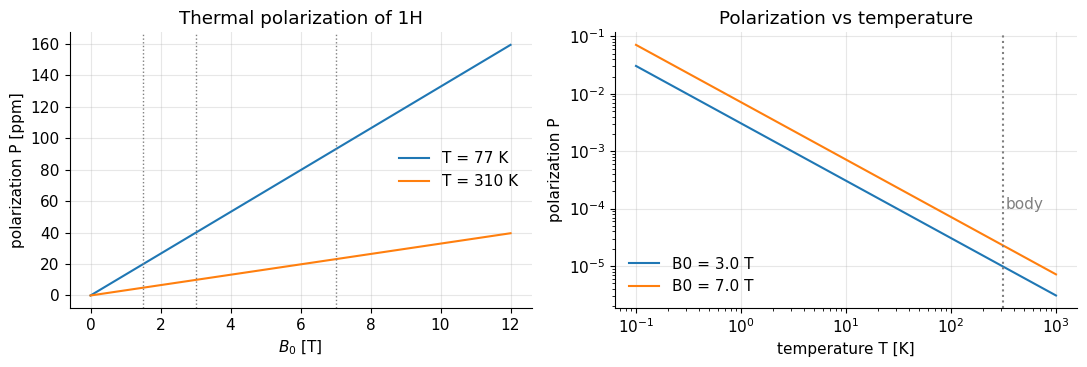

In [6]:
# Polarization versus field strength and temperature
B = np.linspace(0, 12, 200)                                   # T
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for T_K in [77, 310]:
    P = np.tanh(mt.H_PLANCK * mt.GAMMA_BAR * B / (2 * mt.K_BOLTZMANN * T_K))
    ax[0].plot(B, P * 1e6, label=f"T = {T_K} K")
for B_mark in [1.5, 3, 7]:
    ax[0].axvline(B_mark, color="gray", ls=":", lw=1)
ax[0].set_xlabel(r"$B_0$ [T]"); ax[0].set_ylabel("polarization P [ppm]")
ax[0].set_title("Thermal polarization of 1H"); ax[0].legend()

T_range = np.logspace(-1, 3, 300)                              # 0.1 K ... 1000 K
for B_mark in [3.0, 7.0]:
    ax[1].loglog(T_range, np.tanh(mt.H_PLANCK*mt.GAMMA_BAR*B_mark/(2*mt.K_BOLTZMANN*T_range)), label=f"B0 = {B_mark} T")
ax[1].axvline(310, color="gray", ls=":"); ax[1].text(330, 1e-4, "body", color="gray")
ax[1].set_xlabel("temperature T [K]"); ax[1].set_ylabel("polarization P")
ax[1].set_title("Polarization vs temperature"); ax[1].legend()
plt.tight_layout(); plt.show()

Interpretation: polarization grows linearly with $B_0$ (left) and as $1/T$ (right); even liquid-nitrogen temperature (77 K) would only gain a factor 4—and we cannot cool patients. This is the fundamental reason why MRI has low sensitivity and why manufacturers push to higher $B_0$.

> **🔧 Engineering reality:** since signal ∝ $M_0$ ∝ $B_0$ and (as shown in [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)) the induced voltage carries another factor of the precession frequency ∝ $B_0$, the raw signal grows ~$B_0^2$ while body noise grows ~$B_0$, so SNR grows roughly ∝ $B_0$. Each doubling of $B_0$ costs dramatically more superconducting wire, helium/cryogenics, shielding, and creates RF heating (SAR) and field-uniformity problems ([B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb), [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb), [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)). An alternative is **hyperpolarization** (e.g. dissolution dynamic nuclear polarization of ¹³C-labelled molecules, a research focus of the original book's author): polarization is created outside the scanner at ~1 K and several tesla, reaching >10 %, i.e. ~10 000× more than thermal—but it decays with $T_1$ within a minute after injection.

## 3 Resonance

When in a magnetic field, spins—and therefore the net magnetization—experience **magnetic resonance**: they respond strongly to electromagnetic fields of one specific frequency and hardly at all to other frequencies.

### 3.1 The swing analogy

To swing higher and higher you must move your legs back and forth *at the right rate*, the natural rate of the swing. Pumping at the wrong rate barely changes the amplitude, no matter how hard you push. Below is the textbook driven, damped oscillator (a swing with friction): its steady-state amplitude versus the driving frequency.

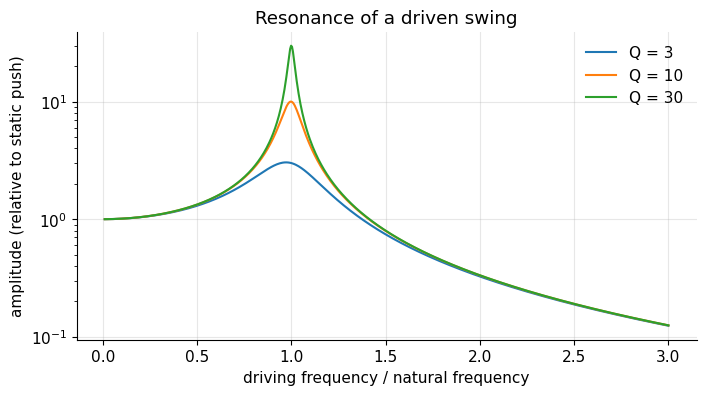

In [7]:
# Driven damped oscillator ("swing"): steady-state amplitude A(w) = F / sqrt((ws^2 - w^2)^2 + (w ws / Q)^2)
ws = 2 * np.pi * 0.5               # natural angular frequency of the swing (period 2 s) [rad/s]
w = np.linspace(0.01, 3, 600) * ws # driving angular frequencies
for Q in [3, 10, 30]:              # quality factor: high Q = little friction
    A = 1.0 / np.sqrt((ws**2 - w**2)**2 + (w * ws / Q)**2)
    plt.plot(w / ws, A * ws**2, label=f"Q = {Q}")
plt.xlabel(r"driving frequency / natural frequency"); plt.ylabel("amplitude (relative to static push)")
plt.title("Resonance of a driven swing"); plt.legend(); plt.yscale("log"); plt.show()

Interpretation: driven at its natural frequency the swing responds with an amplitude $Q$ times larger than a static push; slightly off that frequency the response collapses. Spins behave in the same way: the natural frequency is the Larmor frequency, and the "push" is a small rotating magnetic field $B_1$.

### 3.2 Resonance frequency

The magnetic resonance frequency is proportional to the magnetic field strength experienced by the nucleus:

$$f=\bar\gamma\,\|\vec B\|$$

In words: the resonance (precession) frequency in Hz is gamma-bar times the field magnitude in tesla.

When the field is simply our main field $B_0$, we get the **Larmor frequency**

$$f_0=\bar\gamma B_0\qquad\text{or}\qquad\omega_0=\gamma B_0$$

In words: the Larmor frequency is set by the main field; for protons 42.58 MHz per tesla (63.9 MHz at 1.5 T, 127.7 MHz at 3 T, 298 MHz at 7 T).

where $f_0$ [Hz] is the ordinary and $\omega_0=2\pi f_0$ [rad/s] the angular frequency. Mixing these two up is the most common factor-of-$2\pi$ error in MRI.

### 3.3 Resonance as energy matching (quantum picture)

The same frequency appears from a completely different argument. An electromagnetic wave of frequency $f$ consists of photons of energy $hf$. A photon can flip a spin from the lower to the upper state only if its energy exactly matches the gap:

$$h f=\Delta E=h\bar\gamma B_0\quad\Longrightarrow\quad f=\bar\gamma B_0=f_0$$

In words: the photon energy must equal the energy difference between the two spin states, and that happens exactly at the Larmor frequency.

The classical precession frequency (Section 4) and the quantum transition frequency are the *same* number—a nice consistency check. In practice MRI uses ~$10^{20}$ spins and coherent RF fields, and the **classical picture of a rotating magnetization vector is exact for the net magnetization** (that is what the Bloch equation in [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) describes). We will use the classical picture from now on.

In [8]:
# How energetic are MRI photons? Compare with thermal energy, chemical bonds and X-rays (in electron-volts)
eV = 1.602176634e-19   # J per eV
E_mri = mt.H_PLANCK * mt.larmor_frequency(3.0)
print(f"RF photon at 3 T (127.7 MHz) : {E_mri/eV:.2e} eV")
print(f"thermal energy k_B T (310 K) : {mt.K_BOLTZMANN*310/eV:.3f} eV")
print(f"typical C-C chemical bond     : ~3.6 eV")
print(f"diagnostic X-ray photon       : ~5e4 eV (50 keV)")
print(f"-> an X-ray photon carries ~{5e4*eV/E_mri:.0e} times more energy than an MRI RF photon")

RF photon at 3 T (127.7 MHz) : 5.28e-07 eV
thermal energy k_B T (310 K) : 0.027 eV
typical C-C chemical bond     : ~3.6 eV
diagnostic X-ray photon       : ~5e4 eV (50 keV)
-> an X-ray photon carries ~9e+10 times more energy than an MRI RF photon


Interpretation: MRI photons carry ~$5\times10^{-7}$ eV, millions of times less than needed to break a chemical bond. MRI is therefore **non-ionizing**. Its RF safety issue is different: many photons together deposit heat in tissue (SAR, see [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)).

### 3.4 Excitation by a resonant field

In MRI we perturb the net magnetization from equilibrium by applying a small, time-varying magnetic field $B_1$ (µT, perpendicular to $B_0$) that rotates at the resonance frequency. This "tips" the net magnetization away from its alignment with $B_0$. The animation shows this in the **lab frame** (the frame of the scanner room): the magnetization spirals down while precessing rapidly.

![RF excitation in the lab frame: on-resonance hard pulse](../images/RF_hard_lab_frame_on-resonance.gif)

*RF excitation in the lab frame: a resonant $B_1$ field gradually tips $\vec M$ away from $z$ while $\vec M$ precesses around $B_0$.*

### 3.5 Python demo: resonant versus non-resonant driving

The original chapter asks you to play with the [CompassMR](https://www.drcmr.dk/CompassMR/) simulator (move the $B_1$ field and frequency sliders; only the right frequency produces large oscillations; change $B_0$ and the right frequency changes). It is still a great toy—try it! Here is the same experiment in Python with `mt.bloch_simulate`, which solves the Bloch equation ([A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)) step by step.

To be able to *see* the precession we use a **toy** main field of $B_0=0.47$ mT, so $f_0=20$ kHz instead of 128 MHz; the physics is identical, only the numbers are smaller. We apply $B_1=5.9$ µT ($\bar\gamma B_1=250$ Hz) for 2 ms, rotating in the same sense as the precession (clockwise seen from $+z$; in complex notation $b_1(t)=B_1e^{-i2\pi f_{rf}t}$), at four different RF frequencies $f_{rf}$:

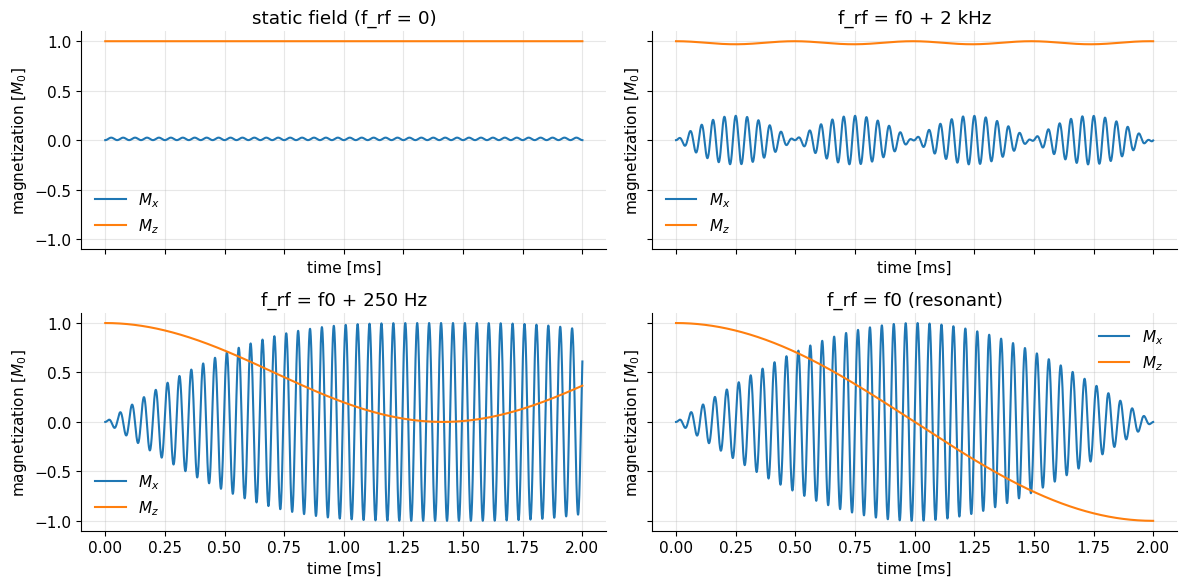

In [9]:
# Lab-frame simulation with a toy B0 so that the precession is visible
f0_toy = 20e3                          # Hz, toy Larmor frequency
B0_toy = f0_toy / mt.GAMMA_BAR         # T  (= 0.47 mT)
B1 = 250 / mt.GAMMA_BAR                # T  (gamma_bar*B1 = 250 Hz -> 180 deg in 2 ms on resonance)
T_pulse, dt = 2e-3, 0.5e-6             # s
t_rf = np.arange(int(T_pulse/dt)) * dt

cases = {"static field (f_rf = 0)": 0.0,
         "f_rf = f0 + 2 kHz": f0_toy + 2000,
         "f_rf = f0 + 250 Hz": f0_toy + 250,
         "f_rf = f0 (resonant)": f0_toy}
fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, (name, f_rf) in zip(axs.ravel(), cases.items()):
    b1 = B1 * np.exp(-1j * 2*np.pi * f_rf * t_rf)        # rotating RF field, Bx + i By
    t, M = mt.bloch_simulate(B1=b1, dt=dt, B0=B0_toy)      # lab frame: B0 included
    mt.plot_magnetization(t, M, ax=ax, title=name, components="xz")
plt.tight_layout(); plt.show()

Interpretation: a static $B_1$ (top left) or one rotating at the wrong frequency (top right) only wobbles $M_z$ by a tiny amount—just like pushing the swing at the wrong rate. Slightly off resonance (bottom left) we tip part-way and come back. Exactly on resonance (bottom right), $M_z$ goes smoothly from +1 to −1 (a 180° flip), while $M_x$ oscillates at 20 kHz because $\vec M$ precesses.

The next cell scans the RF frequency finely and records $M_z$ at the end of the 2 ms pulse. Instead of simulating each RF frequency separately, we keep one RF waveform at $f_0$ and simulate 241 spins whose own Larmor frequency differs by $\Delta f$—physically equivalent, since only the *difference* matters. The black line is the exact formula derived in [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb): off resonance, the spin sees an effective field tilted by $\alpha=\arctan(\bar\gamma B_1/\Delta f)$ from $z$, and $M_z(T)=\cos^2\alpha+\sin^2\alpha\cos(2\pi\sqrt{(\bar\gamma B_1)^2+\Delta f^2}\,T)$.

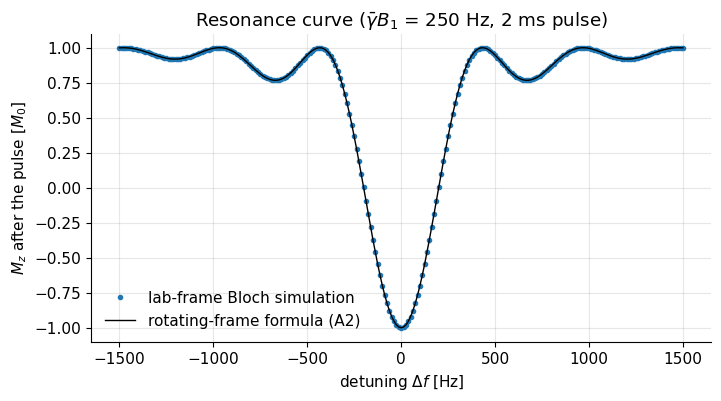

In [10]:
# Resonance curve: Mz after the pulse vs detuning  Delta f = f_spin - f_rf
dfs = np.linspace(-1500, 1500, 241)                     # Hz
b1 = B1 * np.exp(-1j * 2*np.pi * f0_toy * t_rf)          # resonant for the spin with df = 0
t, Mend = mt.bloch_simulate(B1=b1, dt=dt, B0=B0_toy, df=dfs, return_all=False)

gb1 = mt.GAMMA_BAR * B1                                  # 250 Hz
alpha = np.arctan2(gb1, dfs)                             # tilt of effective field
f_eff = np.sqrt(gb1**2 + dfs**2)
Mz_theory = np.cos(alpha)**2 + np.sin(alpha)**2 * np.cos(2*np.pi*f_eff*T_pulse)

plt.plot(dfs, Mend[:, 2], "o", ms=3, label="lab-frame Bloch simulation")
plt.plot(dfs, Mz_theory, "k-", lw=1, label="rotating-frame formula (A2)")
plt.xlabel(r"detuning $\Delta f$ [Hz]"); plt.ylabel(r"$M_z$ after the pulse [$M_0$]")
plt.title(r"Resonance curve ($\bar\gamma B_1$ = 250 Hz, 2 ms pulse)"); plt.legend(); plt.show()

Interpretation: only spins within roughly $\pm\bar\gamma B_1$ (a few hundred Hz) of the RF frequency are flipped; spins detuned by more than ~1 kHz are barely touched. This frequency selectivity is the key to **slice selection** ([E2](../pass2_deep_dive/E2_Slice_Selection.ipynb)): with a field gradient, "frequency" becomes "position".

> **🔧 Engineering reality:** the RF field in a real scanner is produced by the body coil (a "birdcage" resonator) driven by a kilowatt-class RF amplifier (up to ~35 kW peak at 3 T). Typical $B_1$ amplitudes are 10–25 µT, i.e. $10^{-5}$ of $B_0$; the coil must be tuned to $f_0$ exactly, which is why a 3 T coil cannot be used at 1.5 T ([B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)).

## 4 Excitation and precession

### 4.1 Precession

**Precession** is the rotation of the spins, and therefore of the net magnetization, around the magnetic field. Why rotation and not simple alignment? Because the field exerts a torque $\vec\tau=\vec\mu\times\vec B$ on each moment, torque changes angular momentum ($d\vec S/dt=\vec\tau$), and the moment *is* angular momentum times $\gamma$:

$$\frac{d\vec\mu}{dt}=\gamma\frac{d\vec S}{dt}=\gamma\,\vec\mu\times\vec B$$

In words: the change of the moment is always perpendicular to both the moment and the field, so the moment sweeps around the field on a cone—just like a tilted spinning top sweeps around the vertical instead of falling.

The angular frequency of this rotation is $\gamma\|\vec B\|$, *independent of the tilt angle*—it is the same Larmor frequency as above. Adding up all moments in a volume gives the same equation for $\vec M$; this is the first term of the Bloch equation ([A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).

> **🔁 Refresher:** spinning tops and gyroscopes, with a Python demo: [RP3 Precession and torque](../refreshers/RP3_Precession_and_Torque.ipynb).

The precession is what creates the signal: a rotating magnetization is a rotating magnet, its field through a nearby coil changes in time, and by **Faraday's law of induction** this induces a voltage in the coil ([RP2](../refreshers/RP2_Induction_and_RF.ipynb)).

![RF reception](../images/RF_reception.gif)

*The precessing transverse magnetization induces an oscillating voltage in a receive coil.*

### 4.2 Excitation

For the *net* magnetization to precess, it must not be aligned with the field. Individual spins are only *preferentially* aligned, so at any moment many of them precess—but with random phases, so their transverse components cancel and the net magnetization at equilibrium points along $B_0$ and does not precess.

To make the net magnetization precess, a time-varying magnetic field $B_1$ is applied at the resonance frequency (Section 3.5). This tips $\vec M$ away from $B_0$ by the **flip angle** $\theta$; it continues to precess after $B_1$ is turned off. The precessing $\vec M$ creates a time-varying magnetic field that is detected as the MRI signal.

### 4.3 Python demo: "push" the magnetization and listen

CompassMR's "Push" button kicks the needle and you see (and, with the coil enabled, record) its precession. Below we do the same: start with $\vec M$ tipped by 30°, let it precess in a very low toy field ($f_0=100$ Hz, i.e. $B_0=2.3$ µT, about 1/20 of Earth's field) with relaxation switched on, and compute the voltage that a coil whose axis lies along $x$ would pick up. By Faraday's law, the voltage is proportional to $-dM_x/dt$ (the flux through the coil is ∝ $M_x$).

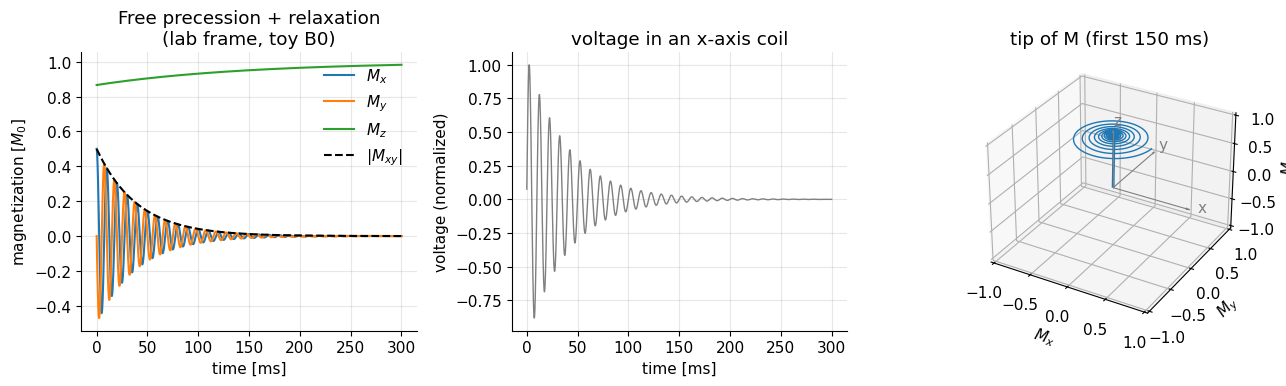

In [11]:
# Free precession after a 30-degree "push", with T1/T2 relaxation (toy numbers for visibility)
f0_push = 100.0                          # Hz
B0_push = f0_push / mt.GAMMA_BAR         # T
theta = np.deg2rad(30)
M_start = [np.sin(theta), 0, np.cos(theta)]
T1, T2 = 0.15, 0.04                      # s (toy values)
dt = 1e-4
t, M = mt.bloch_simulate(n_steps=3000, dt=dt, M_init=M_start, T1=T1, T2=T2, B0=B0_push)
M = M[:, 0, :]
emf = -np.gradient(M[:, 0], dt)          # induced voltage in an x-coil, arbitrary units

fig = plt.figure(figsize=(13, 4))
ax1 = fig.add_subplot(1, 3, 1)
mt.plot_magnetization(t, M, ax=ax1, title="Free precession + relaxation\n(lab frame, toy B0)", components="xyza")
axv = fig.add_subplot(1, 3, 2)
axv.plot(t*1e3, emf/np.abs(emf).max(), color="gray", lw=1)
axv.set_xlabel("time [ms]"); axv.set_ylabel("voltage (normalized)"); axv.set_title("voltage in an x-axis coil")
ax2 = fig.add_subplot(1, 3, 3, projection="3d")
mt.plot_magnetization_3d(M[:1500], ax=ax2, title="tip of M (first 150 ms)")
plt.tight_layout(); plt.show()

Interpretation: $M_x$ and $M_y$ oscillate at $f_0$ (precession) with an envelope $|M_{xy}|$ (dashed) that decays with $T_2$, while $M_z$ slowly climbs back towards 1 with $T_1$ (relaxation). The coil voltage (middle) oscillates at the same frequency—this oscillating voltage, after a lot of electronics, *is* the MRI signal (and is called the free induction decay, FID). The 3D view shows the tip of $\vec M$ spiraling back up to the $z$-axis.

## 5 Relaxation

**Relaxation** is the process by which the net magnetization returns to thermal equilibrium after it has been disturbed. It is governed by two *time constants* (not rates):

* $T_1(\vec r)$, the **longitudinal** or **spin–lattice relaxation time constant**: how fast $M_z$ recovers to $M_0$. It requires the spins to give energy back to their surroundings (the "lattice"), because tipped spins are in a higher-energy state.
* $T_2(\vec r)$, the **transverse** or **spin–spin relaxation time constant**: how fast $M_{xy}$ decays to 0. It is caused by the spins losing phase coherence (getting out of step) because each feels slightly different, fluctuating fields from its neighbours. Anything that causes $T_1$ recovery also destroys phase coherence, so $T_2$ can never be much longer than $T_1$ (the strict theoretical bound is $T_2\le 2T_1$); in tissue $T_2<T_1$ always, usually $T_2\ll T_1$.

These time constants depend on tissue composition and structure, and both are valuable sources of MRI contrast ([D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)). The corresponding *rates* are $R_1=1/T_1$ and $R_2=1/T_2$ [s⁻¹].

![Relaxation](../images/relaxation_t1t2.gif)

*After excitation, $M_{xy}$ decays (T2) much faster than $M_z$ recovers (T1).*

| | Precession | Relaxation |
|---|---|---|
| what happens | $\vec M$ rotates around $\vec B$ | $\vec M$ returns to $[0,0,M_0]$ |
| length of $\vec M$ | unchanged | changes |
| time scale | ~ns per turn (MHz) | ms to s |
| cause | torque of the field on the moments | interactions among spins and with surroundings |
| controlled by us? | yes ($B_0$, gradients, RF) | no—a tissue property (but we choose *when* to look) |

### 5.1 Python demo: relaxation in the rotating frame

CompassMR's last exercise ("Push", then watch the needle return to alignment) is reproduced above. Here are realistic tissue values at 1.5 T. To focus on relaxation, we look at the magnetization in the **rotating frame** ([A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)), which removes the fast precession: after a 90° flip $\vec M$ starts in the transverse plane, then $M_{xy}$ decays and $M_z$ recovers.

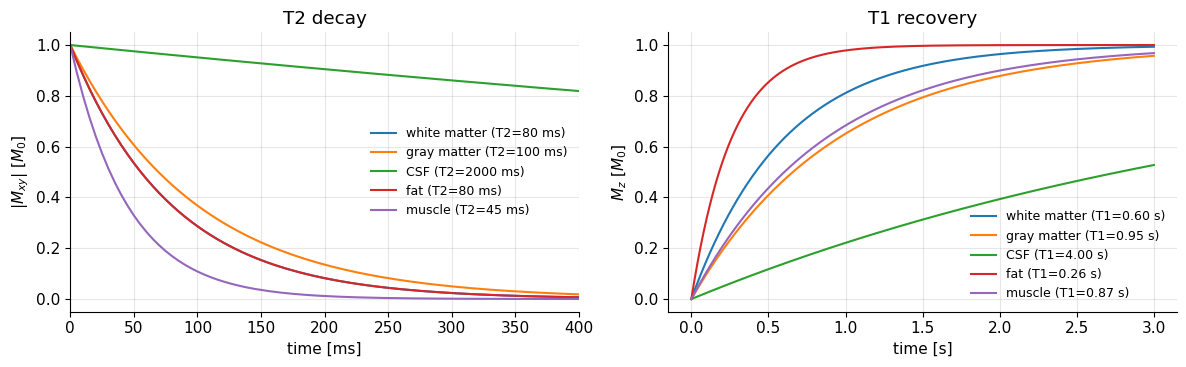

In [12]:
# Approximate relaxation times at 1.5 T (literature ranges vary by ~10-20 %)
tissues = {"white matter": (0.60, 0.080), "gray matter": (0.95, 0.100),
           "CSF": (4.0, 2.0), "fat": (0.26, 0.080), "muscle": (0.87, 0.045)}
t = np.linspace(0, 3, 600)                          # s
M_after = np.array([1.0, 0.0, 0.0])                 # just after a 90-degree flip (rotating frame)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, (T1, T2) in tissues.items():
    Mt = np.array([mt.relax(M_after, ti, T1, T2) for ti in t])   # exact relaxation over time ti
    l, = ax[0].plot(t*1e3, np.abs(Mt[:, 0] + 1j*Mt[:, 1]), label=f"{name} (T2={T2*1e3:.0f} ms)")
    ax[1].plot(t, Mt[:, 2], color=l.get_color(), label=f"{name} (T1={T1:.2f} s)")
ax[0].set_xlim(0, 400); ax[0].set_xlabel("time [ms]"); ax[0].set_ylabel(r"$|M_{xy}|$ [$M_0$]"); ax[0].set_title("T2 decay")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel(r"$M_z$ [$M_0$]"); ax[1].set_title("T1 recovery")
ax[0].legend(fontsize=9); ax[1].legend(fontsize=9); plt.tight_layout(); plt.show()

Interpretation: transverse decay is over in tens to hundreds of ms (note the different time axes), while longitudinal recovery takes seconds. Different tissues separate clearly—this difference is what $T_1$- and $T_2$-weighted images exploit. After one time constant the curves have changed by $1-e^{-1}\approx 63\,\%$.

> **🔧 Engineering reality:** $T_1$ grows with $B_0$ (by ~20–40 % from 1.5 T to 3 T for most tissues), $T_2$ is roughly field-independent. Long $T_1$ forces long waiting times between excitations—the root cause of long MRI scan times ([H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)).

## Key takeaways

* A nuclear **spin** is intrinsic angular momentum; it comes with a **magnetic moment** $\vec\mu=\gamma\vec S$. ¹H ($I=1/2$, $\bar\gamma=42.58$ MHz/T) is by far the most abundant MRI-visible nucleus.
* The **net magnetization** $\vec M$ is the moment per volume [A/m]. At equilibrium it points along $B_0$ with $M_0=N\gamma^2\hbar^2I(I+1)B_0/(3k_BT)$ ≈ 9 mA/m for water at 3 T.
* Only a fraction $P\approx h\bar\gamma B_0/(2k_BT)$ ≈ 10 ppm (3 T) of spins is net aligned; MRI works because there are ~$10^{20}$ protons per mm³.
* **Resonance:** only fields rotating at $f_0=\bar\gamma B_0$ tip $\vec M$ efficiently—classically like pushing a swing at its natural rate, quantum mechanically because $hf_0=\Delta E$.
* **Precession** = rotation of $\vec M$ around $\vec B$ at $f=\bar\gamma\|\vec B\|$ (fast, keeps the length); it induces the signal voltage.
* **Relaxation** = return to equilibrium: $M_{xy}$ decays with $T_2$, $M_z$ recovers with $T_1$ (slow, tissue-dependent → contrast).
* MRI photons (~$10^{-7}$ eV) are non-ionizing; the RF safety concern is heating.

## Check your understanding

1. What is the Larmor frequency of ¹H at 0.55 T, and of ²³Na at 7 T?

<details><summary>Answer</summary>

¹H: $42.58\times0.55\approx 23.4$ MHz. ²³Na: $11.26\times7\approx 78.8$ MHz (see the table in Section 1.2).

</details>

2. By how much does the equilibrium magnetization change when going from 1.5 T to 3 T? From 310 K to 300 K?

<details><summary>Answer</summary>

$M_0\propto B_0/T$: doubling $B_0$ doubles $M_0$. Cooling from 310 to 300 K increases $M_0$ by only $310/300-1\approx 3\,\%$.

</details>

3. A colleague says "at 3 T about half of the protons point up and half point down." Is this right? How large is the excess, as a fraction?

<details><summary>Answer</summary>

Essentially yes—the populations are almost equal. The excess fraction is $P\approx h\bar\gamma B_0/(2k_BT)\approx 1\times10^{-5}$ (10 ppm). Note also that individual spins are not simply "up" or "down" between measurements; the population picture is a statistical statement.

</details>

4. Why does a static (non-oscillating) transverse field of a few µT not tip the magnetization significantly at 3 T?

<details><summary>Answer</summary>

$\vec M$ precesses around the *total* field. Adding a static 5 µT along $x$ to 3 T along $z$ tilts the total field by only $5\times10^{-6}/3$ rad ≈ 0.0001°; $\vec M$ just precesses around this almost-unchanged direction. Only a field that rotates with the precession acts in the same direction all the time and accumulates a large tip (the resonance condition).

</details>

5. After a 90° flip, which happens faster: the loss of signal or the return of $M_z$? What sets the signal frequency?

<details><summary>Answer</summary>

The signal ($M_{xy}$) is lost with $T_2$ (tens of ms in tissue), much faster than $M_z$ recovers with $T_1$ (around a second). The signal frequency is the precession frequency $\bar\gamma\|\vec B\|$, not the relaxation times.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Spin Physics". Changes: defined spin, angular momentum, magnetic moment and γ; corrected the $M_0$ formula notation ($I$ not $I_Z$, $k_B$, $\bar\gamma h=\gamma\hbar$), units of $\vec M$, the ¹H atom fraction (≈62 %, not 80 %) and $N_-$→$N_\downarrow$; added numbers for $M_0$/polarization at 0.55–7 T, the quantum energy-matching view of resonance, and Python demos replacing the CompassMR steps (resonant vs non-resonant driving, resonance curve, free precession with coil voltage, relaxation).*